# SemEval 2025 Task 9: Food Hazard Detection – baseline (1. etapa)

Z hlásenia o sťahovaní potraviny z trhu treba určiť:
- ST1: kategóriu nebezpečenstva (`hazard-category`, 10 tried) a kategóriu produktu (`product-category`, 22 tried),
- ST2: presné nebezpečenstvo (`hazard`, 128 tried) a presný produkt (`product`, vyše 1 000 tried).

Baseline je TF-IDF (cvičenie 3) + logistická regresia (cvičenie 2), na porovnanie aj lineárny SVM.

Postup:
1. načítanie dát a ich analýza,
2. tokenizácia a TF-IDF,
3. výber vstupu (titulok / text / oboje) a váženia tried na validačnej množine,
4. vyhodnotenie na testovacej množine oficiálnou metrikou, uloženie výsledkov a predikcií do `results/`,
5. predikcia pre nový záznam.

Analýza dát, chybová analýza a intervaly spoľahlivosti (bootstrap) sú v `eda_chybova_analyza.ipynb`. Pracuje s predikciami uloženými týmto notebookom, takže sa spúšťa až po ňom.

Beží na CPU, trvá 5–10 minút podľa procesora (najdlhšie logistická regresia pre 1 022 produktov). Výsledky sú na každom stroji rovnaké, líšia sa len časy.

## 0. Importy
Knižnice ako v cvičeniach 2 a 3, modely a metriky zo scikit-learn (Pedregosa et al., 2011). Výstupy sa ukladajú do `results/` v koreni repozitára.

In [1]:
import re, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score

SEED = 42                       # pevné číslo -> rovnaké výsledky pri každom spustení
np.random.seed(SEED)

# výstupy idú do results/ v koreni repozitára (notebook leží v notebooks/)
KOREN = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
VYSLEDKY = os.path.join(KOREN, "results")
os.makedirs(VYSLEDKY, exist_ok=True)

## 1. Načítanie dát

Dáta sú z oficiálneho repozitára úlohy. Súbory `incidents_train.csv`, `incidents_valid.csv` a `incidents_test.csv` sa hľadajú pri notebooku, v `data/` a v `../data/`, inak sa stiahnu z GitHubu.

- train (5 082): trénovanie,
- valid (565): výber nastavení,
- test (997): iba konečné vyhodnotenie, raz. Ladenie podľa testu by výsledok prikrášlilo.

In [2]:
URL = "https://raw.githubusercontent.com/food-hazard-detection-semeval-2025/food-hazard-detection-semeval-2025.github.io/main/data/"

def nacitaj(nazov):
    subor = f"{nazov}.csv"
    for cesta in [subor, os.path.join("data", subor), os.path.join("..", "data", subor)]:
        if os.path.exists(cesta):      # pri notebooku, v data/ alebo v ../data/
            return pd.read_csv(cesta)
    return pd.read_csv(URL + subor)    # inak ho stiahneme

train = nacitaj("incidents_train")
valid = nacitaj("incidents_valid")
test  = nacitaj("incidents_test")
print("train:", train.shape, " valid:", valid.shape, " test:", test.shape)
train[["title", "hazard-category", "product-category", "hazard", "product"]].head()

train: (5082, 11)  valid: (565, 11)  test: (997, 11)


,title,hazard-category,product-category,hazard,product
0,Recall Notification: FSIS-024-94,biological,"meat, egg and dairy products",listeria monocytogenes,smoked sausage
1,Recall Notification: FSIS-033-94,biological,"meat, egg and dairy products",listeria spp,sausage
2,Recall Notification: FSIS-014-94,biological,"meat, egg and dairy products",listeria monocytogenes,ham slices
3,Recall Notification: FSIS-009-94,foreign bodies,"meat, egg and dairy products",plastic fragment,thermal processed pork meat
4,Recall Notification: FSIS-001-94,foreign bodies,"meat, egg and dairy products",plastic fragment,chicken breast


## 2. Analýza dát

Počty tried a ich rozloženie, podľa nich vyberáme metriku.

In [3]:
LABELY = ["hazard-category", "product-category", "hazard", "product"]
for lab in LABELY:
    pocty = train[lab].value_counts()
    print(f"{lab:18s} tried: {len(pocty):5d}   najčastejšia: {pocty.iloc[0]:5d}   "
          f"tried s menej ako 5 príkladmi: {(pocty < 5).sum()}")

hazard-category    tried:    10   najčastejšia:  1854   tried s menej ako 5 príkladmi: 1
product-category   tried:    22   najčastejšia:  1434   tried s menej ako 5 príkladmi: 0
hazard             tried:   128   najčastejšia:   665   tried s menej ako 5 príkladmi: 42
product            tried:  1022   najčastejšia:   185   tried s menej ako 5 príkladmi: 777


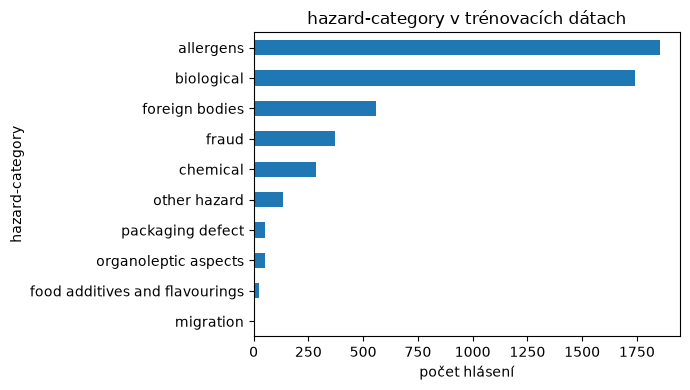

In [4]:
pocty = train["hazard-category"].value_counts()
pocty.plot(kind="barh", figsize=(7, 4), title="hazard-category v trénovacích dátach")
plt.gca().invert_yaxis(); plt.xlabel("počet hlásení"); plt.tight_layout(); plt.show()

In [5]:
dlzka_titulku = train["title"].str.split().str.len()
dlzka_textu   = train["text"].str.split().str.len()
print("titulok: priemer %.0f slov" % dlzka_titulku.mean())
print("text:    medián %.0f slov, maximum %d" % (dlzka_textu.median(), dlzka_textu.max()))

titulok: priemer 13 slov
text:    medián 306 slov, maximum 8406


Zistenia:
- Triedy sú veľmi nevyvážené (napr. *allergens* 1 854-krát, *migration* 3-krát). Accuracy by bola zavádzajúca, používame macro-F1: F1 každej triedy zvlášť a ich priemer, takže každá trieda má rovnakú váhu.
- Pri `product` má veľa tried len 1–2 príklady, ST2 bude oveľa ťažšia.
- Titulok je krátky, text dlhý. Skúsime oba aj ich spojenie.

## 3. Oficiálna metrika

Podľa organizátorov:
1. macro-F1 pre hazard,
2. macro-F1 pre produkt, ale iba na hláseniach so správne predikovaným hazardom,
3. priemer oboch.

Keď je hazard zle, produkt sa nepočíta.

In [6]:
def oficialne_skore(hazard_true, product_true, hazard_pred, product_pred):
    hazard_true, product_true = np.asarray(hazard_true), np.asarray(product_true)
    hazard_pred, product_pred = np.asarray(hazard_pred), np.asarray(product_pred)
    f1_hazard = f1_score(hazard_true, hazard_pred, average="macro")
    spravny_hazard = hazard_pred == hazard_true                    # maska: kde hazard sedí
    f1_product = f1_score(product_true[spravny_hazard], product_pred[spravny_hazard], average="macro")
    return (f1_hazard + f1_product) / 2

def vyhodnot(data, pred):
    # pred = slovník {label: predikcie}
    st1 = oficialne_skore(data["hazard-category"], data["product-category"],
                          pred["hazard-category"], pred["product-category"])
    st2 = oficialne_skore(data["hazard"], data["product"], pred["hazard"], pred["product"])
    vysl = {"ST1": st1, "ST2": st2}
    for lab in pred:
        vysl[lab] = f1_score(data[lab], pred[lab], average="macro")
    return vysl

## 4. Tokenizácia a TF-IDF

- Tokenizer je regex z cvičenia 1: slovo alebo číslo (`\w+`), alebo jeden znak interpunkcie (`[^\w\s]`), všetko malými písmenami.
- TF-IDF ako v cvičení 3 (Manning et al., 2008, kap. 6). `sublinear_tf=True` je logaritmická TF (1 + log f; Manning et al., 2008, kap. 6.4.1), ktorá v cvičení 3 vyšla najlepšie. IDF je vyhladená (štandard v scikit-learn).
- `min_df=2`: slová z jediného hlásenia vynecháme, zmenší sa slovník a vypadnú preklepy.
- Slovník a IDF sa počítajú iba z train (`fit` na train, `transform` na valid/test), aby nedošlo k úniku informácií (data leakage, cvičenie 3).

In [7]:
TOKEN_REGEX = re.compile(r"\w+|[^\w\s]")

def tokenizuj(text):
    return TOKEN_REGEX.findall(text.lower())

def vstup(data, pole):
    # pole: "title", "text" alebo "title+text"
    if pole == "title":
        return data["title"]
    if pole == "text":
        return data["text"]
    return data["title"] + " " + data["text"]

def tfidf(pole):
    vec = TfidfVectorizer(tokenizer=tokenizuj, token_pattern=None, lowercase=False,
                          sublinear_tf=True, min_df=2)
    X_train = vec.fit_transform(vstup(train, pole))   # slovník + IDF iba z train
    X_valid = vec.transform(vstup(valid, pole))
    X_test  = vec.transform(vstup(test, pole))
    return vec, X_train, X_valid, X_test

print(tokenizuj("Recall: Peanut butter (16 oz) may contain Salmonella!"))

['recall', ':', 'peanut', 'butter', '(', '16', 'oz', ')', 'may', 'contain', 'salmonella', '!']


## 5. Modely

Logistická regresia (cvičenie 2; Jurafsky a Martin, *Speech and Language Processing*, 3. vyd., kap. 5): každé slovo má pre každú triedu váhu. Multinomiálna verzia je pri 1 000 produktoch veľmi pomalá, používame one-vs-rest: pre každú triedu samostatný binárny model, vyhrá trieda s najvyššou pravdepodobnosťou.

- `C=10`: slabšia regularizácia. Hodnoty TF-IDF sú malé (pod 1) a silná regularizácia by nedovolila dosť veľké váhy, podobne ako pri relatívnej TF v cvičení 3.
- `class_weight="balanced"`: chyba na zriedkavej triede sa počíta viac, čo pri macro-F1 pomáha.

Lineárny SVM hľadá hranicu s čo najväčším odstupom medzi triedami (scikit-learn používa LIBLINEAR, Fan et al., 2008). Trénuje sa niekoľkonásobne rýchlejšie ako one-vs-rest logistická regresia (časy v kroku 7). Logistická regresia na TF-IDF bola v článku autorov datasetu silný klasický baseline, ktorý pri triedach s malým počtom príkladov predbehol aj transformery RoBERTa a XLM-R (Randl et al., 2024, CICLe; iný, väčší dataset so 7 546 textami).

Majoritný klasifikátor vždy povie najčastejšiu triedu, slúži ako spodná hranica.

In [8]:
def model_lr(vahy=None):
    return OneVsRestClassifier(LogisticRegression(solver="liblinear", C=10, class_weight=vahy, random_state=SEED))

def model_svm(vahy=None):
    return LinearSVC(C=1.0, class_weight=vahy, random_state=SEED)

def natrenuj_a_predikuj(tvorca, X_tr, X_ev, labely=LABELY):
    pred, modely = {}, {}
    for lab in labely:
        model = tvorca()
        model.fit(X_tr, train[lab])
        pred[lab] = model.predict(X_ev)
        modely[lab] = model              # použije sa pri novom zázname (krok 8)
    return pred, modely

## 6. Výber nastavení na validačnej množine

3 vstupy × 2 spôsoby váženia tried.

- SVM trénujeme na všetkých 4 labeloch (ST1 aj ST2).
- Logistickú regresiu kvôli času iba na ST1 (2 labely s 10 a 22 triedami). Na ST2 ju spustíme až s vybraným nastavením v kroku 7.

In [9]:
POLIA = ["title", "text", "title+text"]
VAHY = [None, "balanced"]
matice = {pole: tfidf(pole) for pole in POLIA}
for pole in POLIA:
    print(f"{pole:11s} veľkosť slovníka: {len(matice[pole][0].vocabulary_)}")

title       veľkosť slovníka: 3468
text        veľkosť slovníka: 15087
title+text  veľkosť slovníka: 15180


In [10]:
riadky = []
for pole in POLIA:
    _, X_tr, X_va, _ = matice[pole]
    for v in VAHY:
        t = time.time()
        p, _ = natrenuj_a_predikuj(lambda: model_svm(v), X_tr, X_va)
        r = vyhodnot(valid, p)
        riadky.append({"model": "SVM", "vstup": pole, "váhy tried": v or "žiadne", **r,
                       "čas [s]": round(time.time() - t)})
        t = time.time()
        p, _ = natrenuj_a_predikuj(lambda: model_lr(v), X_tr, X_va, ["hazard-category", "product-category"])
        st1 = oficialne_skore(valid["hazard-category"], valid["product-category"],
                              p["hazard-category"], p["product-category"])
        riadky.append({"model": "LR", "vstup": pole, "váhy tried": v or "žiadne", "ST1": st1,
                       "hazard-category": f1_score(valid["hazard-category"], p["hazard-category"], average="macro"),
                       "product-category": f1_score(valid["product-category"], p["product-category"], average="macro"),
                       "čas [s]": round(time.time() - t)})
porovnanie = pd.DataFrame(riadky)
porovnanie.round(3)

,model,vstup,váhy tried,ST1,ST2,hazard-category,product-category,hazard,product,čas [s]
0,SVM,title,žiadne,0.681,0.387,0.662,0.655,0.458,0.268,10
1,LR,title,žiadne,0.693,NaN,0.663,0.673,NaN,NaN,1
2,SVM,title,balanced,0.633,0.327,0.630,0.600,0.389,0.205,10
3,LR,title,balanced,0.686,NaN,0.681,0.628,NaN,NaN,1
4,SVM,text,žiadne,0.705,0.410,0.724,0.702,0.560,0.237,45
5,LR,text,žiadne,0.684,NaN,0.704,0.626,NaN,NaN,7
6,SVM,text,balanced,0.717,0.393,0.773,0.679,0.577,0.191,49
7,LR,text,balanced,0.697,NaN,0.740,0.684,NaN,NaN,10
8,SVM,title+text,žiadne,0.731,0.429,0.760,0.722,0.586,0.247,43
9,LR,title+text,žiadne,0.707,NaN,0.725,0.650,NaN,NaN,7


In [11]:
najlepsie = porovnanie[porovnanie.model == "SVM"].sort_values("ST1", ascending=False).iloc[0]
print("Najlepšie nastavenie SVM podľa ST1 na validácii:", najlepsie["vstup"], "/", najlepsie["váhy tried"])
najlepsie_lr = porovnanie[porovnanie.model == "LR"].sort_values("ST1", ascending=False).iloc[0]
print("Najlepšie nastavenie LR  podľa ST1 na validácii:", najlepsie_lr["vstup"], "/", najlepsie_lr["váhy tried"])

Najlepšie nastavenie SVM podľa ST1 na validácii: title+text / balanced
Najlepšie nastavenie LR  podľa ST1 na validácii: title+text / balanced


ST1 a ST2 sú oficiálne skóre, ostatné stĺpce macro-F1 jednotlivých labelov. Časy sa medzi modelmi porovnať nedajú (SVM 4 labely, LR 2), porovnateľné sú v kroku 7. Vyberáme riadok s najvyšším ST1 (hlavné poradie súťaže), podľa validácie, nie testu.

## 7. Konečné vyhodnotenie na testovacej množine

Modely s vybraným nastavením natrénujeme na train a raz vyhodnotíme na test.

Na porovnanie s organizátormi pridávame aj modely iba na titulku. Organizátori svoj baseline (TF-IDF + LR: ST1 0,498, ST2 0,183; BERT: ST1 0,667, ST2 0,165) trénovali iba na titulku (Randl et al., 2025, *SemEval-2025 Task 9: The Food Hazard Detection Challenge*, sekcia 3.1 a tabuľky výsledkov, https://arxiv.org/abs/2503.19800). Pre titulok berieme váženie tried, ktoré bolo pre titulok najlepšie na validácii.

Čas zahŕňa trénovanie a predikciu všetkých 4 labelov. Závisí od procesora, porovnávať sa dá len v rámci jedného behu.

In [12]:
def nastavenie(riadok):
    return riadok["vstup"], (None if riadok["váhy tried"] == "žiadne" else "balanced")

def najlepsi_riadok(model, pole=None):
    r = porovnanie[porovnanie.model == model]
    if pole is not None:
        r = r[r.vstup == pole]
    return r.sort_values("ST1", ascending=False).iloc[0]

vysledky, casy, predikcie, modely = {}, {}, {}, {}

def spusti(nazov, tvorca, pole):
    _, X_tr, _, X_te = matice[pole]
    t = time.time()
    pred, mod = natrenuj_a_predikuj(tvorca, X_tr, X_te)
    casy[nazov] = round(time.time() - t)
    vysledky[nazov] = vyhodnot(test, pred)
    predikcie[nazov], modely[nazov] = pred, mod

# spodná hranica
spusti("Majoritná trieda", lambda: DummyClassifier(strategy="most_frequent"), "title")

# najlepšie nastavenia z validácie (titulok + text)
pole, v = nastavenie(najlepsi_riadok("SVM"))
spusti(f"SVM ({pole}, {v or 'bez váh'})", lambda: model_svm(v), pole)
pole_lr, v_lr = nastavenie(najlepsi_riadok("LR"))
spusti(f"LR ({pole_lr}, {v_lr or 'bez váh'})", lambda: model_lr(v_lr), pole_lr)

# iba titulok – rovnaký vstup ako baseline organizátorov
_, v_t = nastavenie(najlepsi_riadok("SVM", "title"))
spusti(f"SVM (title, {v_t or 'bez váh'})", lambda: model_svm(v_t), "title")
_, v_tl = nastavenie(najlepsi_riadok("LR", "title"))
spusti(f"LR (title, {v_tl or 'bez váh'})", lambda: model_lr(v_tl), "title")

NAZOV_SVM = f"SVM ({pole}, {v or 'bez váh'})"
NAZOV_LR = f"LR ({pole_lr}, {v_lr or 'bez váh'})"
pred_svm, pred_lr, modely_lr = predikcie[NAZOV_SVM], predikcie[NAZOV_LR], modely[NAZOV_LR]

tabulka = pd.DataFrame(vysledky).T[["ST1", "ST2"] + LABELY]
tabulka["čas [s]"] = pd.Series(casy)
tabulka.round(3)

,ST1,ST2,hazard-category,product-category,hazard,product,čas [s]
Majoritná trieda,0.035,0.001,0.054,0.022,0.002,0.000,0
"SVM (title+text, balanced)",0.723,0.410,0.763,0.682,0.585,0.220,51
"LR (title+text, balanced)",0.717,0.406,0.743,0.692,0.555,0.247,268
"SVM (title, bez váh)",0.663,0.363,0.638,0.683,0.426,0.260,10
"LR (title, bez váh)",0.633,0.329,0.600,0.664,0.358,0.247,24


Výsledky ukladáme do `results/summary.csv`, aby sa čísla v správe dali skontrolovať bez spúšťania notebooku.

Predikcie oboch vybraných modelov na teste idú do `results/predikcie_test.csv` (stĺpce `SVM|hazard-category`, …, `LR|product`; `id` je poradie hlásenia v `incidents_test.csv`, číslované od 0). Z nich pracuje `eda_chybova_analyza.ipynb`, takže chybová analýza rozoberá tie isté predikcie ako tabuľka vyššie.

In [13]:
tabulka.round(4).to_csv(os.path.join(VYSLEDKY, "summary.csv"), index_label="model")

predikcie_test = pd.DataFrame({"id": np.arange(len(test))})
for skratka, nazov in [("SVM", NAZOV_SVM), ("LR", NAZOV_LR)]:
    for lab in LABELY:
        predikcie_test[f"{skratka}|{lab}"] = predikcie[nazov][lab]
predikcie_test.to_csv(os.path.join(VYSLEDKY, "predikcie_test.csv"), index=False)

print(open(os.path.join(VYSLEDKY, "summary.csv"), encoding="utf-8").read())
print("predikcie_test.csv:", predikcie_test.shape)

model,ST1,ST2,hazard-category,product-category,hazard,product,čas [s]
Majoritná trieda,0.0352,0.0014,0.0536,0.022,0.0021,0.0002,0
"SVM (title+text, balanced)",0.7225,0.4097,0.7631,0.6825,0.585,0.2202,51
"LR (title+text, balanced)",0.717,0.4063,0.7431,0.6917,0.5551,0.2472,268
"SVM (title, bez váh)",0.6634,0.3631,0.6382,0.683,0.4261,0.2596,10
"LR (title, bez váh)",0.6335,0.3285,0.5999,0.6645,0.3575,0.2469,24

predikcie_test.csv: (997, 9)


Analýza chýb a spoľahlivosť výsledkov sú v `eda_chybova_analyza.ipynb`: matica zámen, najčastejšie zamieňané triedy, 20 chýb s ručným komentárom, výkon podľa počtu trénovacích príkladov triedy, nevidené triedy a párový bootstrap rozdielu SVM − LR. 95 % interval rozdielu obsahuje nulu v ST1 aj ST2, ani jeden model nie je preukázateľne lepší.

## 8. Nový záznam

Vymyslené hlásenie prevedieme tým istým vektorizérom na TF-IDF a modely predikujú všetky 4 labely.

In [14]:
nove_hlasenie = ("Company recalls chocolate chip cookies because they may contain undeclared peanuts. "
                 "People who have an allergy to peanuts run the risk of serious reaction.")

vec = matice[pole_lr][0]                    # ten istý vektorizér (slovník + IDF z train)
x_nove = vec.transform([nove_hlasenie])
for lab in LABELY:
    model = modely_lr[lab]                  # modely natrénované v kroku 7
    pravd = model.predict_proba(x_nove)[0].max()
    print(f"{lab:18s} -> {model.predict(x_nove)[0]}   (pravdepodobnosť {pravd:.2f})")

hazard-category    -> allergens   (pravdepodobnosť 0.99)
product-category   -> cereals and bakery products   (pravdepodobnosť 0.46)
hazard             -> peanuts and products thereof   (pravdepodobnosť 0.56)


product            -> cookies   (pravdepodobnosť 0.23)
